# Notebook 1 -- IoT Data Processing & Machine Learning Pipelines

**Course: Embedded Sensors and IoT**

---

### Learning Objectives
1. Load and explore IoT sensor data with **Pandas**
2. Apply the most common **data pre-processing** techniques
3. Build a **train/test split pipeline**
4. Train and evaluate a **regression model** (predicting energy consumption)
5. Train and evaluate a **classification model** (predicting machine failure)
6. Interpret key **ML metrics** for both task types

### Dataset -- IoT Sensor Data (synthetic, 2000 rows)

| Column | Description | Unit |
|---|---|---|
| `timestamp` | 10-min intervals | datetime |
| `temperature_c` | Ambient temperature | Celsius |
| `humidity_pct` | Relative humidity | % |
| `vibration_ms2` | Vibration amplitude | m/s2 |
| `current_draw_a` | Electrical current | Amperes |
| `pressure_kpa` | Atmospheric pressure | kPa |
| `energy_kwh` | Energy consumed -- **regression target** | kWh |
| `machine_failure` | Failure flag -- **classification target** | 0/1 |


## Section 1 -- Environment Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve
)

pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.3f}'.format)
plt.rcParams['figure.figsize'] = (10, 4)
sns.set_theme(style='whitegrid')

print('All libraries imported successfully')

Matplotlib is building the font cache; this may take a moment.


All libraries imported successfully


## Section 2 -- Loading & Exploring the Data

**Pandas** is the core library for tabular data. Key operations:
`pd.read_csv()`, `.head()`, `.info()`, `.describe()`, `.isnull().sum()`

In [2]:
df = pd.read_csv('iot_sensor_data.csv', parse_dates=['timestamp'])
print(f'Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
df.head()

Dataset shape: 2,000 rows x 8 columns


,timestamp,temperature_c,humidity_pct,vibration_ms2,current_draw_a,pressure_kpa,energy_kwh,machine_failure
0,2024-01-01 00:00:00,20.750,57.970,0.214,1.943,101.283,2.384,0
1,2024-01-01 00:10:00,19.820,59.570,0.297,2.185,101.048,2.482,0
2,2024-01-01 00:20:00,21.030,57.620,0.302,2.029,101.214,2.530,0
3,2024-01-01 00:30:00,22.380,59.070,0.347,2.226,101.657,2.381,0
4,2024-01-01 00:40:00,19.770,54.320,0.163,2.393,101.939,2.646,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   timestamp        2000 non-null   datetime64[us]
 1   temperature_c    1940 non-null   float64       
 2   humidity_pct     1940 non-null   float64       
 3   vibration_ms2    1940 non-null   float64       
 4   current_draw_a   1940 non-null   float64       
 5   pressure_kpa     1940 non-null   float64       
 6   energy_kwh       2000 non-null   float64       
 7   machine_failure  2000 non-null   int64         
dtypes: datetime64[us](1), float64(6), int64(1)
memory usage: 125.1 KB


In [4]:
df.describe()

,timestamp,temperature_c,humidity_pct,vibration_ms2,current_draw_a,pressure_kpa,energy_kwh,machine_failure
count,2000,1940.000,1940.000,1940.000,1940.000,1940.000,2000.000,2000.000
mean,2024-01-07 22:35:00,21.058,49.974,0.350,2.693,101.304,2.934,0.095
min,2024-01-01 00:00:00,10.950,31.610,0.001,0.699,99.339,1.086,0.000
25%,2024-01-04 11:17:30,16.990,43.560,0.237,2.180,100.982,2.457,0.000
50%,2024-01-07 22:35:00,20.770,50.050,0.310,2.553,101.311,2.809,0.000
75%,2024-01-11 09:52:30,24.102,56.440,0.393,3.010,101.630,3.198,0.000
max,2024-01-14 21:10:00,43.310,69.700,1.240,6.476,102.989,6.485,1.000
std,NaN,5.032,7.566,0.198,0.808,0.494,0.757,0.293


In [5]:
# Missing value audit -- critical for IoT data (sensors drop out!)
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
report = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print(report[report['Missing Count'] > 0])

                Missing Count  Missing %
temperature_c              60      3.000
humidity_pct               60      3.000
vibration_ms2              60      3.000
current_draw_a             60      3.000
pressure_kpa               60      3.000


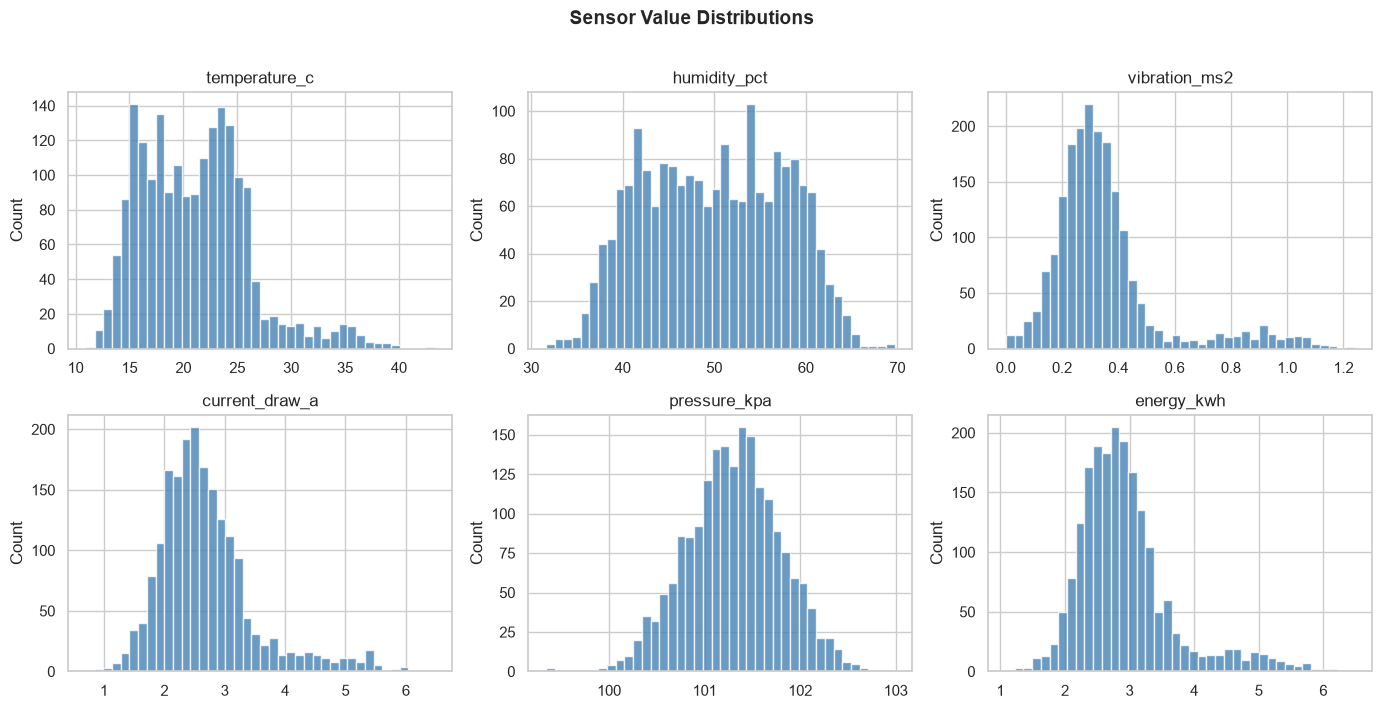

In [6]:
# Distribution of each sensor
sensor_cols = ['temperature_c', 'humidity_pct', 'vibration_ms2',
               'current_draw_a', 'pressure_kpa', 'energy_kwh']

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flatten(), sensor_cols):
    ax.hist(df[col].dropna(), bins=40, color='steelblue', edgecolor='white', alpha=0.8)
    ax.set_title(col)
    ax.set_ylabel('Count')
plt.suptitle('Sensor Value Distributions', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

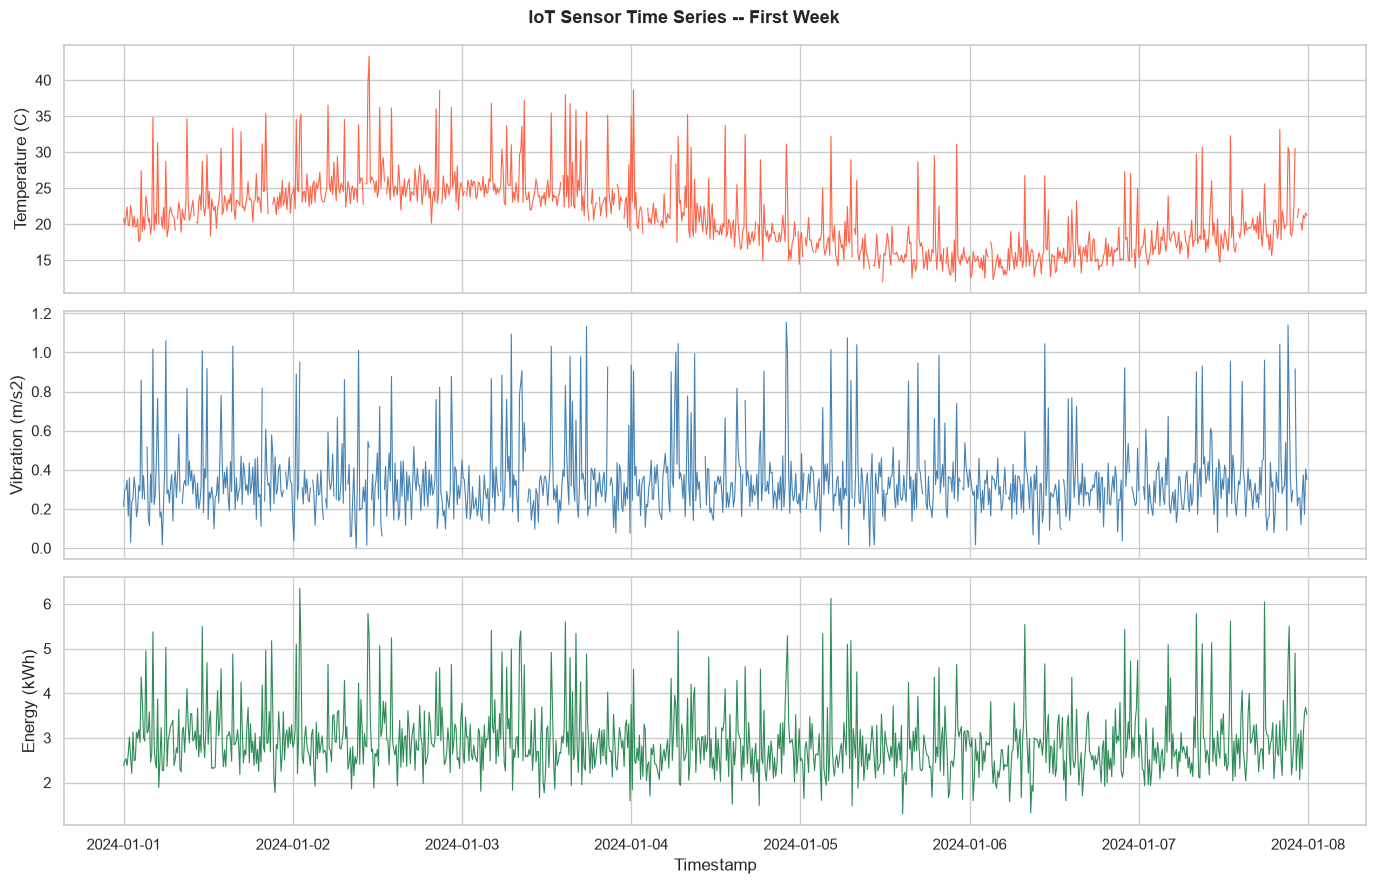

In [7]:
# Time-series view -- first week
week = df[df['timestamp'] < df['timestamp'].min() + pd.Timedelta(days=7)]

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
axes[0].plot(week['timestamp'], week['temperature_c'], color='tomato', lw=0.8)
axes[0].set_ylabel('Temperature (C)')
axes[1].plot(week['timestamp'], week['vibration_ms2'], color='steelblue', lw=0.8)
axes[1].set_ylabel('Vibration (m/s2)')
axes[2].plot(week['timestamp'], week['energy_kwh'], color='seagreen', lw=0.8)
axes[2].set_ylabel('Energy (kWh)')
axes[2].set_xlabel('Timestamp')
plt.suptitle('IoT Sensor Time Series -- First Week', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Section 3 -- Data Pre-Processing

| Step | Why it matters |
|---|---|
| 1. Feature engineering | Extract useful signals from raw columns |
| 2. Imputation | Models cannot accept NaN |
| 3. Outlier treatment | Extreme values distort learning |
| 4. Correlation analysis | Understand which features matter |
| 5. Feature scaling | Puts all features on equal footing |


### Step 1 -- Feature Engineering from Timestamp

In [ ]:
# Extract time-based features to capture diurnal and weekly patterns
df['hour']        = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek   # 0=Monday
df['is_weekend']  = (df['day_of_week'] >= 5).astype(int)

print('New time features:')
print(df[['timestamp', 'hour', 'day_of_week', 'is_weekend']].head(8))

In [ ]:
hourly_energy = df.groupby('hour')['energy_kwh'].mean()

plt.figure(figsize=(10, 4))
plt.bar(hourly_energy.index, hourly_energy.values, color='steelblue', edgecolor='white')
plt.xlabel('Hour of Day')
plt.ylabel('Avg Energy (kWh)')
plt.title('Average Energy Consumption by Hour of Day')
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

### Step 2 -- Handling Missing Values (Imputation)

**Median imputation**: fill NaN with the column median.
Median is preferred over mean because it is robust to outliers -- important for skewed sensor data.

In [ ]:
sensor_cols = ['temperature_c', 'humidity_pct', 'vibration_ms2',
               'current_draw_a', 'pressure_kpa']

medians = df[sensor_cols].median()
print('Medians used for imputation:')
print(medians.round(3))

df[sensor_cols] = df[sensor_cols].fillna(medians)
print(f'\nMissing values remaining: {df.isnull().sum().sum()}')

### Step 3 -- Outlier Detection & Treatment

**IQR Method** (non-parametric, no normal distribution assumed):
- IQR = Q3 - Q1
- Outlier bounds: [Q1 - 1.5*IQR, Q3 + 1.5*IQR]

**Treatment: Capping (Winsorization)** -- clip values to the bounds instead of dropping rows.
This preserves sample size, critical when failure events are rare.

In [ ]:
def iqr_bounds(series):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    return Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

print(f"{'Column':<20} {'Lower':>10} {'Upper':>10} {'# Outliers':>12}")
print('-' * 55)
for col in sensor_cols:
    lo, hi = iqr_bounds(df[col])
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f'{col:<20} {lo:>10.3f} {hi:>10.3f} {n_out:>12,}')

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, col in zip(axes, sensor_cols):
    ax.boxplot(df[col], patch_artist=True,
               boxprops=dict(facecolor='steelblue', alpha=0.6),
               medianprops=dict(color='red', linewidth=2))
    ax.set_title(col, fontsize=9)
plt.suptitle('Box Plots -- Outlier Visualization (whiskers = 1.5xIQR)', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
df_clean = df.copy()
for col in sensor_cols:
    lo, hi = iqr_bounds(df[col])
    df_clean[col] = df[col].clip(lower=lo, upper=hi)

print('Outlier capping applied. Shape unchanged:', df_clean.shape)

### Step 4 -- Correlation Analysis

In [ ]:
feature_cols = sensor_cols + ['hour', 'day_of_week', 'is_weekend',
                               'energy_kwh', 'machine_failure']
corr = df_clean[feature_cols].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Feature Correlation Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Features most correlated with energy_kwh:')
print(corr['energy_kwh'].sort_values(ascending=False).drop('energy_kwh').round(3))

### Step 5 -- Feature Scaling (Standardization)

StandardScaler: z = (x - mean) / std -- transforms each feature to mean=0, std=1.

**Key rule**: Fit the scaler ONLY on training data, then transform both train and test.
Fitting on all data = **data leakage** (the model has seen test set statistics before evaluation).

## Section 4 -- Train / Test Split

We never evaluate a model on data it was trained on -- that would be like giving students the exam answers.

**Standard split: 80% train / 20% test**
`stratify=y` ensures class proportions are preserved in both splits -- vital for imbalanced failure data.

In [ ]:
FEATURES = ['temperature_c', 'humidity_pct', 'vibration_ms2',
            'current_draw_a', 'pressure_kpa', 'hour', 'day_of_week', 'is_weekend']

X     = df_clean[FEATURES]
y_reg = df_clean['energy_kwh']
y_clf = df_clean['machine_failure']

print(f'Feature matrix X:          {X.shape}')
print(f'Regression target:         {y_reg.shape}')
print(f'Classification target:     {y_clf.shape}')
print(f'\nFailure rate: {y_clf.mean()*100:.1f}% -- imbalanced dataset!')

In [ ]:
X_train, X_test, yr_train, yr_test = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)
_, _, yc_train, yc_test = train_test_split(
    X, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

print(f'Training set:  {X_train.shape[0]:,} rows ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Test set:      {X_test.shape[0]:,} rows ({X_test.shape[0]/len(X)*100:.0f}%)')
print(f'\nClass balance in train: {yc_train.mean()*100:.1f}% failure')
print(f'Class balance in test:  {yc_test.mean()*100:.1f}% failure  <- stratify preserved the ratio!')

In [ ]:
# CRITICAL: fit on TRAIN only, transform both
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)      # NOT fit_transform!

before = pd.DataFrame(X_train, columns=FEATURES).describe().loc[['mean','std']]
after  = pd.DataFrame(X_train_scaled, columns=FEATURES).describe().loc[['mean','std']]

print('BEFORE scaling:')
print(before.round(2))
print('\nAFTER scaling (all means ~0, all stds ~1):')
print(after.round(2))

## Section 5 -- Regression: Predicting Energy Consumption

**Task**: given sensor readings, predict `energy_kwh` -- a continuous value.

**Model**: Linear Regression
Fits a hyperplane: y_hat = b0 + b1*x1 + b2*x2 + ... + bn*xn

Simple and interpretable -- always a good baseline before trying complex models.

In [ ]:
reg_model = LinearRegression()
reg_model.fit(X_train_scaled, yr_train)
yr_pred = reg_model.predict(X_test_scaled)

print('Linear Regression trained.')
sample = pd.DataFrame({'Actual': yr_test.values[:5], 'Predicted': yr_pred[:5]})
print(sample.round(4))

### Regression Metrics

| Metric | Interpretation |
|---|---|
| **MAE** | Average error in same units as target. Easy to explain to stakeholders. |
| **MSE** | Squares errors -- penalises large errors more heavily |
| **RMSE** | Square root of MSE -- back in original units |
| **R-squared** | % of variance explained. 1.0 = perfect, 0 = no better than just predicting the mean. |

In [ ]:
mae  = mean_absolute_error(yr_test, yr_pred)
mse  = mean_squared_error(yr_test, yr_pred)
rmse = np.sqrt(mse)
r2   = r2_score(yr_test, yr_pred)

print('=' * 40)
print('  REGRESSION METRICS')
print('=' * 40)
print(f'  MAE:   {mae:.4f} kWh')
print(f'  MSE:   {mse:.4f}')
print(f'  RMSE:  {rmse:.4f} kWh')
print(f'  R2:    {r2:.4f}')
print('=' * 40)
print(f'\nOn average, predictions are off by {mae:.3f} kWh')
print(f'The model explains {r2*100:.1f}% of variance in energy consumption')

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Actual vs Predicted
ax1.scatter(yr_test, yr_pred, alpha=0.35, s=15, color='steelblue', label='Predictions')
lims = [min(yr_test.min(), yr_pred.min()), max(yr_test.max(), yr_pred.max())]
ax1.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction')
ax1.set_xlabel('Actual Energy (kWh)')
ax1.set_ylabel('Predicted Energy (kWh)')
ax1.set_title('Actual vs Predicted')
ax1.legend()

# Residuals
residuals = yr_test.values - yr_pred
ax2.scatter(yr_pred, residuals, alpha=0.35, s=15, color='tomato')
ax2.axhline(0, color='black', linewidth=1.5, linestyle='--')
ax2.set_xlabel('Predicted Energy (kWh)')
ax2.set_ylabel('Residual (Actual - Predicted)')
ax2.set_title('Residual Plot')

plt.suptitle('Linear Regression Diagnostics', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('A good residual plot shows no pattern -- errors should be random around 0.')

In [ ]:
coef_df = pd.DataFrame({
    'Feature': FEATURES,
    'Coefficient': reg_model.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

plt.figure(figsize=(8, 4))
colors = ['steelblue' if c >= 0 else 'tomato' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors, edgecolor='white')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coefficient Value')
plt.title('Linear Regression -- Feature Coefficients')
plt.tight_layout()
plt.show()

print('Larger absolute value = stronger influence on prediction.')
print(coef_df.to_string(index=False))

## Section 6 -- Classification: Predicting Machine Failure

**Task**: predict `machine_failure` (0=OK, 1=Failure) from sensor readings.

**Model**: Random Forest Classifier -- ensemble of decision trees.
Handles non-linear patterns and provides built-in feature importance.

Our dataset is imbalanced (~90% OK, ~10% Failure).
`class_weight='balanced'` prevents the model from just always predicting OK.

In [ ]:
clf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
clf_model.fit(X_train_scaled, yc_train)

yc_pred      = clf_model.predict(X_test_scaled)
yc_pred_prob = clf_model.predict_proba(X_test_scaled)[:, 1]

print('Random Forest trained.')
print(f'Sample predictions (first 10): {yc_pred[:10]}')
print(f'Failure probability (first 10): {yc_pred_prob[:10].round(3)}')

### Classification Metrics Explained

For every prediction one of four outcomes occurs:

|  | Predicted Positive | Predicted Negative |
|---|---|---|
| **Actual Positive** | TP -- correctly caught failure | FN -- MISSED failure (dangerous!) |
| **Actual Negative** | FP -- false alarm | TN -- correctly said OK |

| Metric | Formula | When to use |
|---|---|---|
| **Accuracy** | (TP+TN)/Total | Only when classes are balanced |
| **Precision** | TP/(TP+FP) | When false alarms are costly |
| **Recall** | TP/(TP+FN) | When missing a failure is costly (most important here) |
| **F1 Score** | 2*P*R/(P+R) | Balance of precision and recall |
| **ROC-AUC** | Area under ROC curve | Overall discriminative ability |

In [ ]:
acc  = accuracy_score(yc_test, yc_pred)
prec = precision_score(yc_test, yc_pred)
rec  = recall_score(yc_test, yc_pred)
f1   = f1_score(yc_test, yc_pred)
auc  = roc_auc_score(yc_test, yc_pred_prob)

print('=' * 45)
print('  CLASSIFICATION METRICS')
print('=' * 45)
print(f'  Accuracy:   {acc:.4f}  ({acc*100:.1f}%)')
print(f'  Precision:  {prec:.4f}')
print(f'  Recall:     {rec:.4f}')
print(f'  F1 Score:   {f1:.4f}')
print(f'  ROC-AUC:    {auc:.4f}')
print('=' * 45)

recall_pct  = rec * 100
missed_pct  = (1 - rec) * 100
prec_pct    = prec * 100

print(f'Recall {rec:.0%}: the model catches {recall_pct:.0f}% of actual failures')
print(f'Missing {missed_pct:.0f}% of failures could cause unplanned downtime.')
print(f'Precision {prec:.0%}: when it predicts failure, it is right {prec_pct:.0f}% of the time')
print(f'AUC {auc:.3f}: strong ability (0.5=random, 1.0=perfect)')

In [ ]:
print('Detailed Classification Report:')
print(classification_report(yc_test, yc_pred,
                             target_names=['No Failure (0)', 'Failure (1)']))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Confusion Matrix
cm = confusion_matrix(yc_test, yc_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred: OK', 'Pred: Fail'],
            yticklabels=['True: OK', 'True: Fail'])
axes[0].set_title('Confusion Matrix')

# ROC Curve
fpr, tpr, _ = roc_curve(yc_test, yc_pred_prob)
axes[1].plot(fpr, tpr, color='steelblue', linewidth=2, label=f'ROC (AUC = {auc:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
axes[1].fill_between(fpr, tpr, alpha=0.1, color='steelblue')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].set_title('ROC Curve')
axes[1].legend()

# Feature Importance
fi = pd.Series(clf_model.feature_importances_, index=FEATURES).sort_values()
axes[2].barh(fi.index, fi.values, color='seagreen', edgecolor='white')
axes[2].set_xlabel('Importance Score')
axes[2].set_title('Random Forest Feature Importance')

plt.suptitle('Classification Model Diagnostics', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# How confident is the model? Separation between classes
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(yc_pred_prob[yc_test == 0], bins=40, alpha=0.65, color='steelblue', label='True: No Failure')
ax.hist(yc_pred_prob[yc_test == 1], bins=40, alpha=0.65, color='tomato', label='True: Failure')
ax.axvline(0.5, color='black', linestyle='--', label='Decision threshold (0.5)')
ax.set_xlabel('Predicted Probability of Failure')
ax.set_ylabel('Count')
ax.set_title('Predicted Probability Distribution by True Class')
ax.legend()
plt.tight_layout()
plt.show()

print('Good separation between distributions = confident, reliable model.')
print('In production: lower the threshold (e.g. 0.3) to catch more failures')
print('at the cost of more false alarms. This is a business decision.')

## Section 7 -- Summary & Pipeline Recap

---

### The Complete ML Pipeline

```
Raw IoT Data (CSV)
       |
       v
1. LOAD & EXPLORE      -> pd.read_csv(), .info(), .describe(), .isnull()
       |
       v
2. FEATURE ENGINEERING -> Extract hour, day_of_week, is_weekend from timestamp
       |
       v
3. IMPUTATION          -> Fill NaN with column medians
       |
       v
4. OUTLIER TREATMENT   -> IQR capping (Winsorization)
       |
       v
5. TRAIN / TEST SPLIT  -> 80/20, random_state=42, stratify for classification
       |
       v
6. SCALING             -> StandardScaler fit on TRAIN only, transform BOTH
       |
       +------------------------------+
       |                              |
       v                              v
REGRESSION MODEL            CLASSIFICATION MODEL
(LinearRegression)          (RandomForestClassifier)
       |                              |
       v                              v
MAE, RMSE, R2               Accuracy, Precision, Recall,
Residual plots              F1, AUC, Confusion Matrix
```

---

### When to Use Each Metric

| Scenario | Recommended Metric |
|---|---|
| Regression, outliers present | MAE (robust) |
| Regression, large errors are very bad | RMSE |
| Regression overall fit | R-squared |
| Classification, balanced classes | Accuracy |
| Classification, missing failures is costly | **Recall** |
| Classification, false alarms are costly | Precision |
| Classification, balanced score needed | F1 |
| Classification, probability ranking matters | ROC-AUC |

---

### Next Steps
- Hyperparameter tuning with `GridSearchCV` / `RandomizedSearchCV`
- Cross-validation (k-fold) for more robust evaluation
- Handling severe class imbalance with SMOTE
- Time-series aware train/test splitting for IoT data

---
*Notebook 1 -- IoT ML Course | Data Processing & Pipelines*